![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/05/logo-upv-horizontal.png)
![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/06/logos-perte-chip-1024x119.png)


# Laboratory 1. Waveguides

Welcome to our Photonic Integrated Circuits Laboratory! Throughout the course, we will be using a Python package called [GDSFactory](https://gdsfactory.github.io/gdsfactory/index.html). This is an open-source tool, and is a great alternative to other commercial software like Synopsys Optodesigner, Luceda Photonics, or Lumerical/Interconnect. Since it runs on Python, you have two options for executing your laboratory tasks:

1. **Local installation on your own PC** (Recommended): Please note that we will not spend class time on installing the software. However, feel free to reach out if you need help with the installation.

2. **Cloud Workspace**: Alternatively, you can use a cloud-based solution if the Local installation does not work.

## 0. Imports

For this laboratory you will need the following libraries:

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import tidy3d as td

import gplugins as gp
import gplugins.tidy3d as gt
from gplugins import plot
from gplugins.common.config import PATH

nm = 1e-3
wavelength = np.linspace(1500, 1600,11) * nm
f = td.C_0 / wavelength


In [2]:
nitride_complex = td.material_library["Si3N4"]["Luke2015PMLStable"].eps_model(f)
nitride_index, nitride_k = td.Medium.eps_complex_to_nk(nitride_complex)
box_complex = td.material_library["SiO2"]["Horiba"].eps_model(f)
box_index, box_k = td.Medium.eps_complex_to_nk(box_complex)

## LO.1. Effective index of a waveguide

### Convergence Tests
We have asumed until now, that the **real** value of the effective index for each cross-section is the value provided by this mode-solver. However, this number relies on a numerical method, making it sensible to some input parameters, such as the selected grid. The objective of this section is to find the dependence of the **calculated** value of the effective index with the *grid_resolution* and the *max_grid_scaling*, the two parameters that we can modify from the automatic grid function used at the gt.modes.Waveguide() function.  <br>
- Consider a 1.2 um width deep waveguide (SiNx), with 0.3 um height operating at 1550 nm.
    - Sweep the *grid_resolution* between 10 and 100 in steps of 10. Plot the **calculated** effective index vs the *grid_resolution*. 
    - Select a value for the *grid_resolution* from the latter sweep (where the calculated index remains almost constant), and sweep the *max_grid_scaling* from 1.2 to 1.6 in steps of 0.1. Plot the **calculated** effective index vs the *max_grid_scaling*.
    - Conclude which will be the best configuration for the grid parameters for this particular case. 

In [3]:
grid_resolution = np.linspace(10,100,10)
max_grid_scaling = np.linspace(1.2,1.6,6)

In [4]:
n_eff = []
fraction_te = []

for grid_res in grid_resolution:
    deep_waveguide = gt.modes.Waveguide(
        # Geometrical Parameters
        core_width=1.2, # Waveguide width
        core_thickness=300 * nm, # Waveguide height 
        slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
        # Materials
        core_material='sin', #  Material of the waveguide
        clad_material='sio2', # Surrounding material
        # Modesolver Parameters
        wavelength=1550 * nm, # Wavelength to simulate
        num_modes=4, # Targeted number of modes to find 
        max_grid_scaling=1.5, # Parameters of the grid 
        grid_resolution=grid_res, # Parameters of the grid
        cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
        precision='double',
    )

    #deep_waveguide.plot_index()
    n_eff.append(deep_waveguide.n_eff)
    fraction_te.append(deep_waveguide.fraction_te)

2026-11-05 18:00:15.439 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_13fe960528db7e9b.npz.
2026-11-05 18:00:15.537 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_cf92515ae4232c65.npz.
2026-11-05 18:00:15.545 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_152975b7cd7bd92b.npz.
2026-11-05 18:00:15.552 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_721700b7522a7617.npz.
2026-11-05 18:00:15.559 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_0ea6c3bb3b1c00e8.npz.
2026-11-05 18:00:15.566 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_67a04e2475ce3436.npz.
2026-11-05 18:00:15.572 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_b110164ae7f9a70a.npz.
2026-11-05 18:00:15.580 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_c8d8b6bf9be8a3e8.npz.


In [5]:
fraction_te

[array([0.99474718, 0.00926039, 0.968749  , 0.0480113 ]),
 array([0.99505426, 0.01004259, 0.96264794, 0.047651  ]),
 array([0.99575806, 0.00918099, 0.96351813, 0.04146956]),
 array([0.99589059, 0.00872346, 0.96181774, 0.04150954]),
 array([0.99601247, 0.00853277, 0.95991595, 0.04265049]),
 array([0.99631531, 0.00807737, 0.95990672, 0.04206394]),
 array([0.99653994, 0.00766236, 0.95932394, 0.04098711]),
 array([0.99651728, 0.00757823, 0.95900442, 0.04126066]),
 array([0.99674561, 0.00732726, 0.95931703, 0.04065949]),
 array([0.99693292, 0.00705645, 0.95942541, 0.04044323])]

In [6]:
n_eff_TE0 = []
for i in range(len(n_eff)):
    n_eff_TE0.append(n_eff[i][0].real)

C:\Users\user\AppData\Local\Temp\ipykernel_6688\1637776511.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper left', bbox_to_anchor=(1, 1))


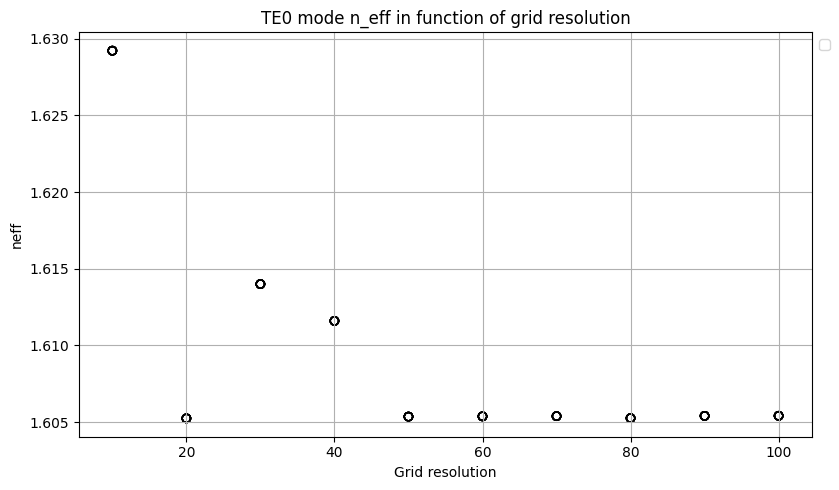

In [7]:
plt.figure(figsize=(10, 5))
for k in range(len(grid_resolution)):
    # It's necessary to 'access' each element on the array
    plt.scatter(grid_resolution, n_eff_TE0,edgecolors='k',facecolors='none',label = '__nolegend__')
    #plt.plot(grid_resolution, n_eff_TE0,label=f'Mode {k}')
plt.title(f"TE0 mode n_eff in function of grid resolution")
plt.xlabel("Grid resolution")
plt.ylabel("neff")
plt.grid()
#plt.plot(grid_resolution, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

Entiendo que a partir de 50 el neff converge a un valor más o menos estable. Por lo que decido usar el valor 20, el mínimo que me da esa estabilidad

In [8]:
n_eff = []
fraction_te = []
for max_grid in max_grid_scaling:
    deep_waveguide = gt.modes.Waveguide(
        # Geometrical Parameters
        core_width=1.2, # Waveguide width
        core_thickness=300 * nm, # Waveguide height 
        slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
        # Materials
        core_material='sin', #  Material of the waveguide
        clad_material='sio2', # Surrounding material
        # Modesolver Parameters
        wavelength=1550 * nm, # Wavelength to simulate
        num_modes=4, # Targeted number of modes to find 
        max_grid_scaling=max_grid, # Parameters of the grid 
        grid_resolution=30, # Parameters of the grid
        cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
        precision='double',
    )

    #deep_waveguide.plot_index()
    n_eff.append(deep_waveguide.n_eff)
    fraction_te.append(deep_waveguide.fraction_te)

2026-11-05 18:00:29.415 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_baa76e6c7700d8eb.npz.
2026-11-05 18:00:29.425 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_31d447fb1b4aa12e.npz.
2026-11-05 18:00:29.432 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_57979ec95d5d9bbb.npz.
2026-11-05 18:00:29.440 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_51d7613b6f014081.npz.
2026-11-05 18:00:29.447 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_0d3f56b7f6adaf9c.npz.
2026-11-05 18:00:29.455 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_11c3e180b944c2ef.npz.


In [9]:
n_eff_TE0 = []
for i in range(len(n_eff)):
    n_eff_TE0.append(n_eff[i][0].real)

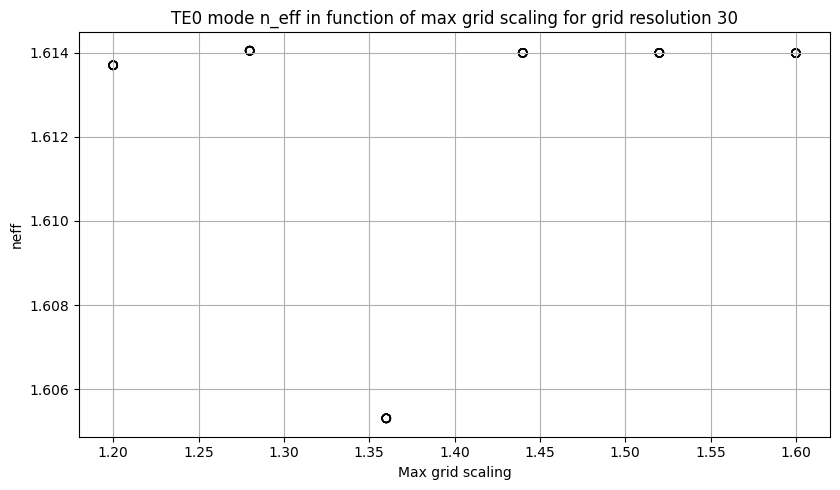

In [10]:
plt.figure(figsize=(10, 5))
for k in range(len(max_grid_scaling)):
    # It's necessary to 'access' each element on the array
    plt.scatter(max_grid_scaling, n_eff_TE0,edgecolors='k',facecolors='none',label = '__nolegend__')
    #plt.plot(max_grid_scaling, n_eff_TE0,label=f'Mode {k}')
plt.title(f"TE0 mode n_eff in function of max grid scaling for grid resolution 30")
plt.xlabel("Max grid scaling")
plt.ylabel("neff")
plt.grid()
#plt.plot(grid_resolution, box_index,'k--', label='SiO2 index')
#plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

Esto es con un grid que no converge, 30. Me dice que este valor no converge excepto un valor de max grid scaling concreto, muy sensible al error. Aquí se ve la importancia de hacer fine tuning de lo sparámetros. Determinará la robustez de tus resultados

C:\Users\user\AppData\Local\Temp\ipykernel_6688\1334806636.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper left', bbox_to_anchor=(1, 1))


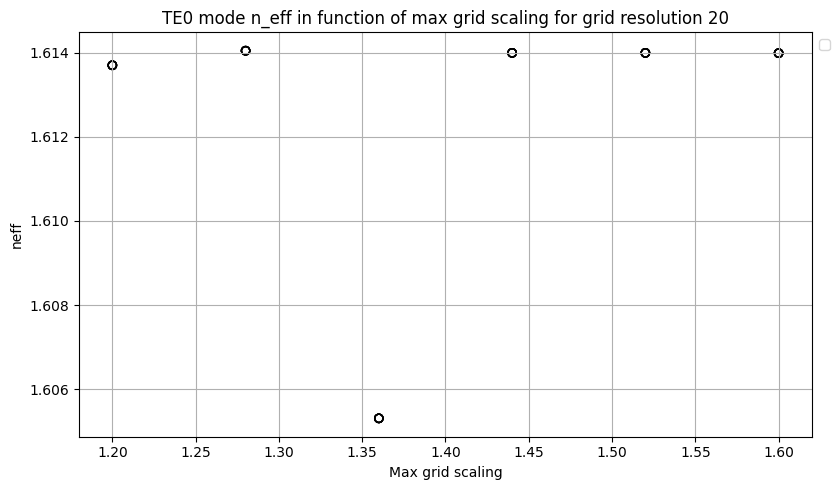

In [11]:
plt.figure(figsize=(10, 5))
for k in range(len(max_grid_scaling)):
    # It's necessary to 'access' each element on the array
    plt.scatter(max_grid_scaling, n_eff_TE0,edgecolors='k',facecolors='none',label = '__nolegend__')
    #plt.plot(max_grid_scaling, n_eff_TE0,label=f'Mode {k}')
plt.title(f"TE0 mode n_eff in function of max grid scaling for grid resolution 20")
plt.xlabel("Max grid scaling")
plt.ylabel("neff")
plt.grid()
#plt.plot(grid_resolution, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

El tiempo de ejecución entre 1.2 y 1.4 max scalling no es muy grande, puedo coger 1.4 que parece más cercano al valor convergente. Se obsera que 1.5 y 1.6 ya divergen del neff óptimo

In [3]:
import time

In [15]:
start = time.perf_counter()
deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=1.2, # Waveguide width
    core_thickness=300 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=4, # Targeted number of modes to find 
    max_grid_scaling=1.2, # Parameters of the grid 
    grid_resolution=20, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
    )
end = time.perf_counter()
print(f"Execution time: {end - start} seconds")

Execution time: 0.00013580001541413367 seconds


In [14]:
start = time.perf_counter()
deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=1.2, # Waveguide width
    core_thickness=300 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=4, # Targeted number of modes to find 
    max_grid_scaling=1.4, # Parameters of the grid 
    grid_resolution=20, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
    )
end = time.perf_counter()
print(f"Execution time: {end - start} seconds")

Execution time: 0.00014059999375604093 seconds


As we saw before, the time execution difference between max grid scaling 1.2 and 1.4 is very small, of the order of 10e-5 secons

## LO.2. Width dependence

- Perform a sweep of the **deep** waveguide width. Use the code provided in the following cell or program your own sweep. 

  0%|          | 0/11 [00:00<?, ?it/s]

2026-11-05 20:39:29.449 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_a1188177df9d4412.npz.
2026-11-05 20:39:29.451 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_eaf8803b7dd0ab21.npz.
2026-11-05 20:39:29.452 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d65d3bf0b50545c0.npz.
2026-11-05 20:39:29.453 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_10f7023e62ba3f62.npz.
2026-11-05 20:39:29.455 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_92d005b8bcbdcd88.npz.
2026-11-05 20:39:29.457 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_fd3ef6feb17ea835.npz.
2026-11-05 20:39:29.459 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_3fc9fcf961f2ad42.npz.
2026-11-05 20:39:29.461 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_2936a0a7e236aac8.npz.


  0%|          | 0/11 [00:00<?, ?it/s]

2026-11-05 20:39:29.470 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_a1188177df9d4412.npz.
2026-11-05 20:39:29.472 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_eaf8803b7dd0ab21.npz.
2026-11-05 20:39:29.475 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d65d3bf0b50545c0.npz.
2026-11-05 20:39:29.477 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_10f7023e62ba3f62.npz.
2026-11-05 20:39:29.478 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_92d005b8bcbdcd88.npz.
2026-11-05 20:39:29.480 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_fd3ef6feb17ea835.npz.
2026-11-05 20:39:29.481 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_3fc9fcf961f2ad42.npz.
2026-11-05 20:39:29.483 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_2936a0a7e236aac8.npz.


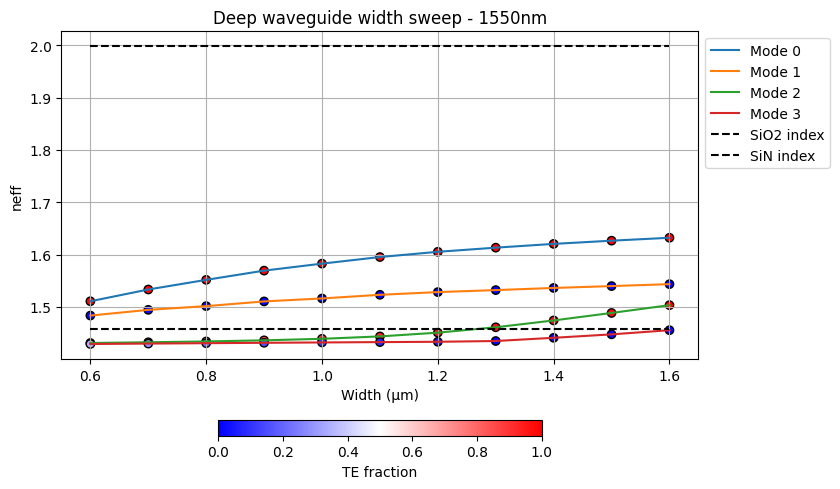

In [155]:
wavelength = 1550 * nm # Student code here

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=1.2,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    slab_thickness=0 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.4,
    grid_resolution=20, 
)

w = np.linspace(0.6,1.6,11) # Student code here

sweep_neff = gt.modes.sweep_n_eff(deep_waveguide, 
                             core_width=w)

sweep_tefraction = gt.modes.sweep_fraction_te(deep_waveguide,
                                              core_width=w)

plt.figure(figsize=(10, 5))
for k in range(sweep_neff.shape[1]):
    plt.scatter(w, sweep_neff[:,k].real,edgecolors='k',c=sweep_tefraction.sel(mode_index=k),vmin=0, vmax=1,label = '__nolegend__',cmap='bwr')
    plt.plot(w, sweep_neff[:,k].real,label=f'Mode {k}')

plt.title("Deep waveguide width sweep - 1550nm")
plt.xlabel("Width (μm)")
plt.ylabel("neff")
plt.grid()
plt.hlines(np.mean(box_index), xmin=np.min(w), xmax=np.max(w), colors='k', linestyles='dashed',label='SiO2 index')
plt.hlines(np.mean(nitride_index), xmin=np.min(w), xmax=np.max(w), colors='k', linestyles='dashed',label='SiN index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.colorbar(orientation='horizontal',fraction=0.04).set_label("TE fraction")

It's clear how the mode 2 only are able to be guided starting width = 1.3 microns. So for Te polarization, the waveguide will stop to be monomode for widths grater than 1.3 microns. However, for the TM polarization, we see how the second TM mode (Mode 3 on the plot) is not guided for any width consideren in thi range, the guide, with the considered geometry and width range is monomode for TM polarization

## LO.3. Waveguide compact model

A compact model of an integrated photonic waveguide is a reduced-order mathematical model that describes the waveguide’s optical behavior—such as phase propagation, loss, and dispersion, using analytical or semi-analytical equations. Consider: 

Transfer function for propagation in a waveguide:

$$
H(\lambda)
= e^{-j\,\beta(\lambda)\,z}
= e^{-j\,\mathrm{Re}\{\beta(\lambda)\}\,z}\,
  e^{\mathrm{Im}\{\beta(\lambda)\}\,z}.
$$

Where 

$$
\beta(\lambda)
= \frac{2\pi}{\lambda}\,\mathrm{Re}\{n_\mathrm{eff}(\lambda)\}.
$$

Let's model the waveguide's effective index wavelength variation using a second order polynomial:

$$
n_\mathrm{eff}(\lambda)
= n_{1} + n_{2}\,(\lambda-\lambda_{0}) + n_{3}\,(\lambda-\lambda_{0})^{2}
$$

Where 

1. 
$$
n_\mathrm{eff}(\lambda_0) = n_1
$$
2. 
$$
n_g(\lambda_0) = n_1 - n_2\,\lambda_0
$$
3. 
$$
D = -\frac{2\,\lambda_0\,n_3}{c}\;\;[\mathrm{s}^2/\mathrm{m}]
$$

- Find the **compact models** of the following waveguides: 
    - Deep waveguide, height = 300nm, width = 1.2um 
    - Shallow waveguide, core height = 300nm, slab height = 150 nm, width = 1.2um 

**TIP**. Use the Lab0.1.Modesolver results (neff vs lambda) as starting point. Fit the results using a second order polynomial (with the lambda_0 shift) and relate the fit results to n_g and D values.

### Deep waveguide

2026-11-05 18:01:34.725 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_453210b0140a829a.npz.


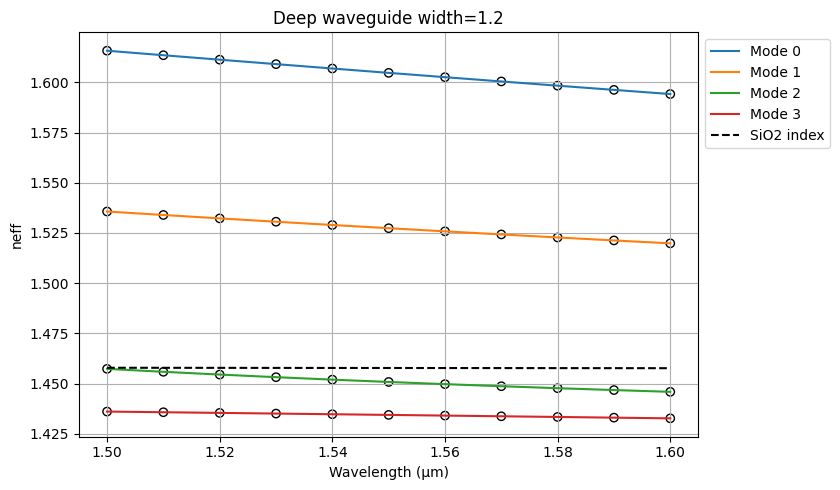

In [17]:
# The wavelength could be a vector also
wavelength = np.linspace(1500, 1600,11) * nm

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength, 
    core_width=1.2, 
    slab_thickness=0.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.4,
    grid_resolution=20, 
)

res_neff = deep_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te = deep_waveguide.fraction_te # Wavelength-dependent vector
res_tm =deep_waveguide.fraction_tm # Wavelength-dependent vector

plt.figure(figsize=(10, 5))
for k in range(res_neff.shape[1]):
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength, res_neff[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, res_neff[:,k].real,label=f'Mode {k}')
plt.title(f"Deep waveguide width={1.2}")
plt.xlabel("Wavelength (μm)")
plt.ylabel("neff")
plt.grid()
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

As we see, beff with lambda follows a linear dependency. We do a second order linear fit for the two modes that are guided (TE0 and TM0). We have to take in account that the fit is done centered to a lamda_0. So I have to shift the values

In [18]:
lambda_0 = 1550
wavelength = wavelength = np.linspace(1500, 1600,11) 
wavelength = wavelength -1550
wavelength = wavelength * nm
print(wavelength)

[-0.05 -0.04 -0.03 -0.02 -0.01  0.    0.01  0.02  0.03  0.04  0.05]


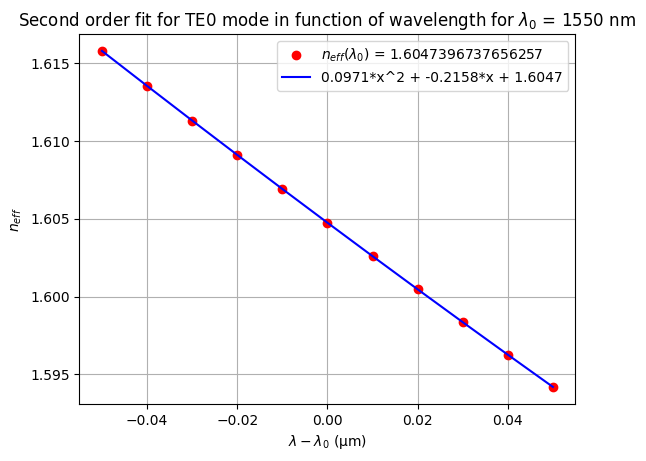

In [19]:
# Ajuste a segundo orden 
lambda_0_latex = r'\lambda_0'
neff_latex = r'n_{eff}'
plt.plot(wavelength,res_neff[:,0].real,'ro',label=f'${neff_latex}$(${lambda_0_latex}$) = {res_neff[5,0].real}')

p = np.polyfit(wavelength,res_neff[:,0].real,2)
plt.plot(wavelength,np.polyval(p, wavelength),color='blue',label=f'{round(p[0], 4)}*x^2 + {round(p[1], 4)}*x + {round(p[2], 4)}')
lambda_0_latex = r'\lambda_0'
plt.title(f"Second order fit for TE0 mode in function of wavelength for ${lambda_0_latex}$ = 1550 nm")
latex = r'\lambda-\lambda_0'
plt.xlabel(f'${latex}$ (μm)')
neff_latex = r'n_{eff}'
plt.ylabel(f'${neff_latex}$')
plt.grid()
plt.legend()
plt.show()

In [20]:
print(res_neff[5,0].real)
print(p)
ng_TE0 = p[2]-p[1]*lambda_0*nm
D = -2*lambda_0*nm*p[0]/(3*10**14) #La velocidad en micras por segundo!
print(f"neff_TE0_deep = {p[2]}")
print(f"ng_TE0_deep= {ng_TE0}")
print(f"D_TE0_deep = {D}")

1.6047396737656257
[ 0.09710981 -0.2157782   1.60473968]
neff_TE0_deep = 1.6047396802144442
ng_TE0_deep= 1.9391958912786222
D_TE0_deep = -1.0034680071099973e-15


In [25]:
from IPython.display import display, Math

ng_TE0 = p[2] - p[1] * lambda_0 * nm
D = -2 * lambda_0 * nm * p[0] / (3 * 10**14)
D_m = D*1e12
# Display results in LaTeX format
display(Math(rf'n_{{\mathrm{{eff,TE0}}}} = {p[2]:.6f}'))

display(Math(rf'n_{{g,\mathrm{{TE0}}}} = {ng_TE0:.6f}\;\frac{{1}}{{\mu m}}'))

display(Math(rf'D_{{\mathrm{{TE0}}}} = {D_m:.6f}\;\frac{{s}}{{m^2}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

La ordenada es el neff de la longitud de onda central que hemos cogido! Vamos con el TM

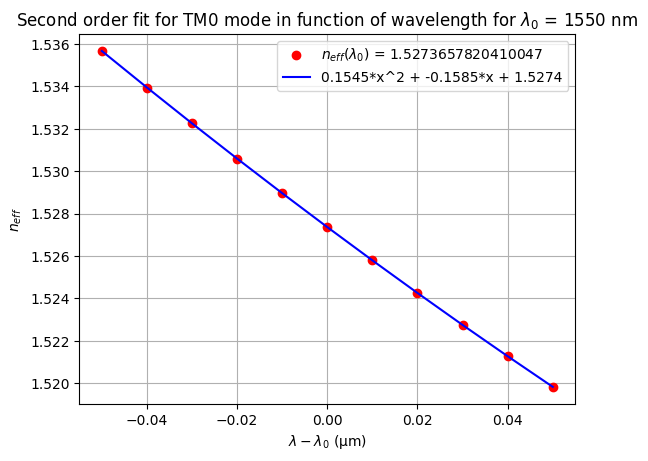

In [26]:
# Ajuste a segundo orden 
lambda_0_latex = r'\lambda_0'
neff_latex = r'n_{eff}'
plt.plot(wavelength,res_neff[:,1].real,'ro',label=f'${neff_latex}$(${lambda_0_latex}$) = {res_neff[5,1].real}')

p_TM = np.polyfit(wavelength,res_neff[:,1].real,2)
plt.plot(wavelength,np.polyval(p_TM, wavelength),color='blue',label=f'{round(p_TM[0], 4)}*x^2 + {round(p_TM[1], 4)}*x + {round(p_TM[2], 4)}')
lambda_0_latex = r'\lambda_0'
plt.title(f"Second order fit for TM0 mode in function of wavelength for ${lambda_0_latex}$ = 1550 nm")
plt.xlabel(f'${latex}$ (μm)')
plt.ylabel(f'${neff_latex}$')
plt.grid()
plt.legend()
plt.show()

In [27]:
print(res_neff[5,1].real)
print(p_TM)
ng_TM0 = p_TM[2]-p_TM[1]*lambda_0*nm
D = -2*lambda_0*nm*p_TM[0]/(3*10**14) #La velocidad en micras por segundo!

print(f"neff_TM0_deep = {p_TM[2]}")
print(f"ng_TM0_deep = {ng_TM0}")
print(f"D_TM0_deep = {D}")

1.5273657820410047
[ 0.15449925 -0.15846764  1.52736578]
neff_TM0_deep = 1.5273657833622993
ng_TM0_deep = 1.7729906232168935
D_TM0_deep = -1.5964922734051424e-15


In [28]:
ng_TM0 = p_TM[2] - p_TM[1] * lambda_0 * nm
D = -2 * lambda_0 * nm * p_TM[0] / (3 * 10**14)
D_m = D*1e12
# Display results in LaTeX format
display(Math(rf'n_{{\mathrm{{eff,TM0}}}} = {p_TM[2]:.6f}'))

display(Math(rf'n_{{g,\mathrm{{TM0}}}} = {ng_TM0:.6f}\;\frac{{1}}{{\mu m}}'))

display(Math(rf'D_{{\mathrm{{TM0}}}} = {D_m:.6f}\;\frac{{s}}{{m^2}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

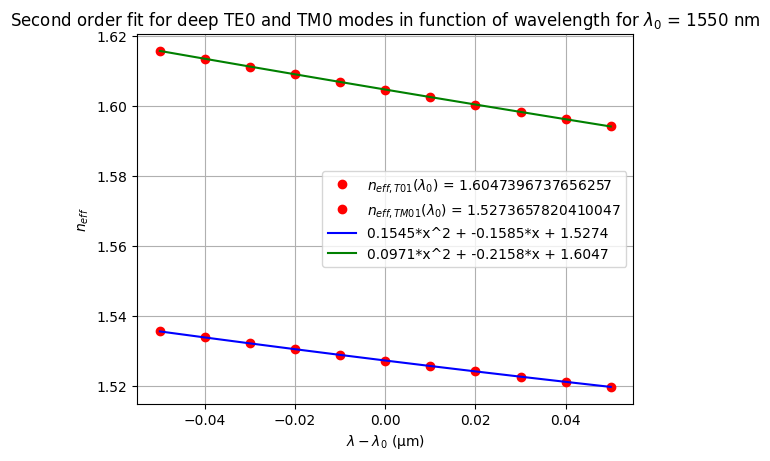

In [29]:
#Combine plot

# Ajuste a segundo orden 
lambda_0_latex = r'\lambda_0'
neff_latex_T01 = r'n_{eff,T01}'
neff_latex_TM01 = r'n_{eff,TM01}'
plt.plot(wavelength,res_neff[:,0].real,'ro',label=f'${neff_latex_T01}$(${lambda_0_latex}$) = {res_neff[5,0].real}')
plt.plot(wavelength,res_neff[:,1].real,'ro',label=f'${neff_latex_TM01}$(${lambda_0_latex}$) = {res_neff[5,1].real}')

p_TM = np.polyfit(wavelength,res_neff[:,1].real,2)
plt.plot(wavelength,np.polyval(p_TM, wavelength),color='blue',label=f'{round(p_TM[0], 4)}*x^2 + {round(p_TM[1], 4)}*x + {round(p_TM[2], 4)}')
p = np.polyfit(wavelength,res_neff[:,0].real,2)
plt.plot(wavelength,np.polyval(p, wavelength),color='green',label=f'{round(p[0], 4)}*x^2 + {round(p[1], 4)}*x + {round(p[2], 4)}')

lambda_0_latex = r'\lambda_0'
plt.title(f"Second order fit for deep TE0 and TM0 modes in function of wavelength for ${lambda_0_latex}$ = 1550 nm")
latex = r'\lambda-\lambda_0'
plt.xlabel(f'${latex}$ (μm)')
neff_latex = r'n_{eff}'
plt.ylabel(f'${neff_latex}$')
plt.grid()
plt.legend()
plt.show()

### Shallow waveguide

#### Convergence Tests

Vamos ahora con la shallow, empecemos con el análisis de convergencia

In [37]:
grid_resolution = np.linspace(10,100,10)
max_grid_scaling = np.linspace(1.2,1.6,5)

In [42]:
n_eff = []
fraction_te = []
for grid_res in grid_resolution:
    deep_waveguide = gt.modes.Waveguide(
        # Geometrical Parameters
        core_width=1.2, # Waveguide width
        core_thickness=300 * nm, # Waveguide height 
        slab_thickness=150 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
        # Materials
        core_material='sin', #  Material of the waveguide
        clad_material='sio2', # Surrounding material
        # Modesolver Parameters
        wavelength=1550 * nm, # Wavelength to simulate
        num_modes=4, # Targeted number of modes to find 
        max_grid_scaling=1.2, # Parameters of the grid 
        grid_resolution=grid_res, # Parameters of the grid
        cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
        precision='double',
    )

    #deep_waveguide.plot_index()
    n_eff.append(deep_waveguide.n_eff)
    fraction_te.append(deep_waveguide.fraction_te)

2026-11-05 18:10:41.242 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_38fbb848e79968d1.npz.
2026-11-05 18:10:41.251 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_285238a48af05435.npz.
2026-11-05 18:10:41.258 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_769eeebadf411c16.npz.
2026-11-05 18:10:41.265 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_ad22b186adaea231.npz.
2026-11-05 18:10:41.271 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_8952042d5cfcaafb.npz.
2026-11-05 18:10:41.278 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_0acdaa8abc194b41.npz.
2026-11-05 18:10:41.280 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_5b9cc6172444fc11.npz.
2026-11-05 18:10:41.287 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_c67d71b6023eb958.npz.


In [43]:
fraction_te

[array([0.99669234, 0.0337741 , 0.96450772, 0.99986048]),
 array([0.99682239, 0.65892443, 0.2205658 , 0.99999635]),
 array([0.99716138, 0.97085753, 0.99987208, 0.0209048 ]),
 array([0.99711652, 0.89732616, 0.05422667, 0.99999387]),
 array([0.99719769, 0.75561388, 0.13943069, 0.99999474]),
 array([0.99732742, 0.87237531, 0.06881998, 0.99998824]),
 array([0.99729214, 0.93524187, 0.03651513, 0.99998451]),
 array([0.99721993, 0.78373782, 0.12316874, 0.99999177]),
 array([0.99748031, 0.86344524, 0.07543889, 0.99998949]),
 array([0.99744883, 0.79235122, 0.11877182, 0.99998998])]

As we can see, there is a big differencde of TE fractions depending the grid resolution value, as we saw at the beginining with the deep waveguide that difference should't be thta big so it seems that something with the modesolver is not working correctly. Let's do a small convergence test for shallow waveguide

In [44]:
n_eff_TE0 = []
for i in range(len(n_eff)):
    n_eff_TE0.append(n_eff[i][0].real)
print(range(len(n_eff_TE0)), range(len(grid_resolution)))

range(0, 10) range(0, 10)


C:\Users\user\AppData\Local\Temp\ipykernel_6688\1637776511.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper left', bbox_to_anchor=(1, 1))


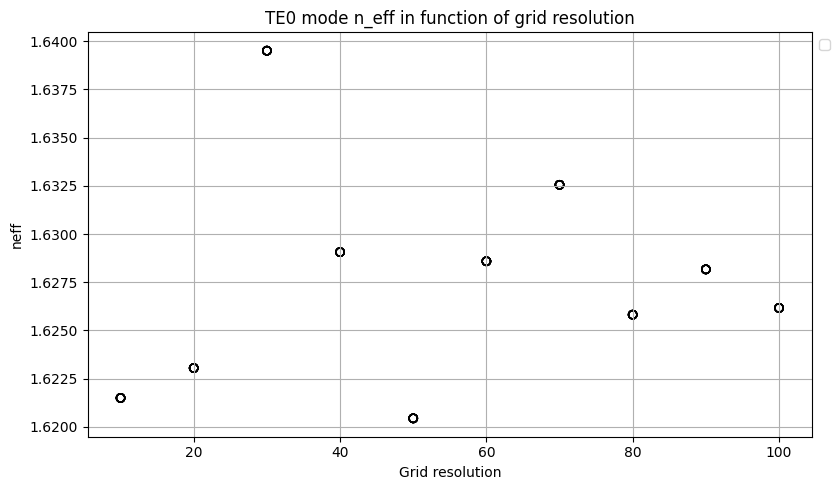

In [45]:
plt.figure(figsize=(10, 5))
for k in range(len(grid_resolution)):
    # It's necessary to 'access' each element on the array
    plt.scatter(grid_resolution, n_eff_TE0,edgecolors='k',facecolors='none',label = '__nolegend__')
    #plt.plot(grid_resolution, n_eff_TE0,label=f'Mode {k}')
plt.title(f"TE0 mode n_eff in function of grid resolution")
plt.xlabel("Grid resolution")
plt.ylabel("neff")
plt.grid()
#plt.plot(grid_resolution, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

In this case we can see there is not a clear convergence for any grid resolution value, it seem that something of the modesolver is not working properly

In [47]:
n_eff = []
fraction_te = []
for max_grid in max_grid_scaling:
    deep_waveguide = gt.modes.Waveguide(
        # Geometrical Parameters
        core_width=1.2, # Waveguide width
        core_thickness=300 * nm, # Waveguide height 
        slab_thickness=150 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
        # Materials
        core_material='sin', #  Material of the waveguide
        clad_material='sio2', # Surrounding material
        # Modesolver Parameters
        wavelength=1550 * nm, # Wavelength to simulate
        num_modes=4, # Targeted number of modes to find 
        max_grid_scaling=max_grid, # Parameters of the grid 
        grid_resolution=20, # Parameters of the grid
        cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
        precision='double',
    )

    #deep_waveguide.plot_index()
    n_eff.append(deep_waveguide.n_eff)
    fraction_te.append(deep_waveguide.fraction_te)

2026-11-05 18:11:46.297 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_285238a48af05435.npz.
2026-11-05 18:11:46.299 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_267cb14405aa4780.npz.
2026-11-05 18:11:46.306 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_3f716aed8b385179.npz.
2026-11-05 18:11:46.308 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_1982ab1e607e2389.npz.
2026-11-05 18:11:46.309 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_de9e48b78be3f2fe.npz.


In [48]:
fraction_te

[array([0.99682239, 0.65892443, 0.2205658 , 0.99999635]),
 array([0.9974526 , 0.92025027, 0.04089212, 0.99998422]),
 array([0.9968256 , 0.61217135, 0.24807513, 0.99999634]),
 array([0.99689796, 0.2230249 , 0.66053185, 0.99998122]),
 array([0.99689541, 0.22287684, 0.66234819, 0.99998139])]

We can see a big difference of the TE fraction in fucntion of the ,ax grid scaling. After a discussion with the professor on class he told me that this is not so habitual so maybe something with this modesolver is not working fine for shallow tranversal sections

In [49]:
n_eff_TE0 = []
for i in range(len(n_eff)):
    n_eff_TE0.append(n_eff[i][0].real)
print(range(len(n_eff_TE0)), range(len(max_grid_scaling)))

range(0, 5) range(0, 5)


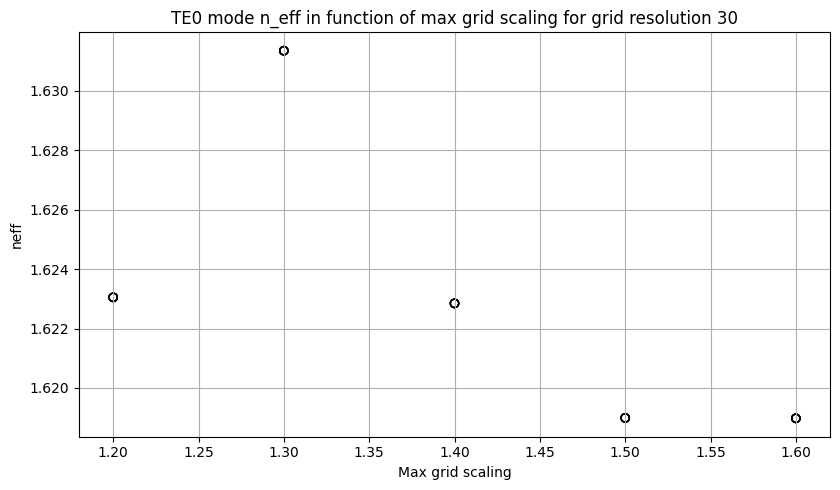

In [51]:
plt.figure(figsize=(10, 5))
for k in range(len(max_grid_scaling)):
    # It's necessary to 'access' each element on the array
    plt.scatter(max_grid_scaling, n_eff_TE0,edgecolors='k',facecolors='none',label = '__nolegend__')
    #plt.plot(max_grid_scaling, n_eff_TE0,label=f'Mode {k}')
plt.title(f"TE0 mode n_eff in function of max grid scaling for grid resolution 30")
plt.xlabel("Max grid scaling")
plt.ylabel("neff")
plt.grid()
#plt.plot(grid_resolution, box_index,'k--', label='SiO2 index')
#plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

From 1.4 we got a convergent solution so thats will be our value to not increase the computation time, but something on this library seems to not work properly in shallow waveguide. We will do again this problem with another solver. The professor told us to do the shallow plots with the same grid parameters as deep waveguide and using the second mode thats it's a hybrid one

#### Compact model

2026-11-05 18:13:45.514 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_7ffbb4c2e95aaca4.npz.


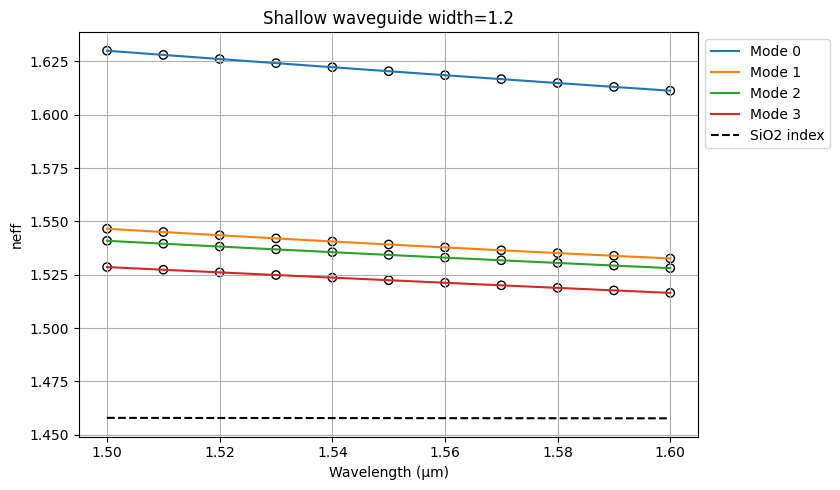

In [53]:
# The wavelength could be a vector also
wavelength_array = np.linspace(1500, 1600,11) * nm

shallow_waveguide = gt.modes.Waveguide(
    wavelength=wavelength_array, 
    core_width=1.2, 
    slab_thickness=150*nm,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.4,
    grid_resolution=20, 
)

res_neff_shallow = shallow_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te_shallow = shallow_waveguide.fraction_te # Wavelength-dependent vector
res_tm_shallow =shallow_waveguide.fraction_tm # Wavelength-dependent vector

plt.figure(figsize=(10, 5))
for k in range(res_neff_shallow.shape[1]):
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength_array, res_neff_shallow[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength_array, res_neff_shallow[:,k].real,label=f'Mode {k}')
plt.title(f"Shallow waveguide width={1.2}")
plt.xlabel("Wavelength (μm)")
plt.ylabel("neff")
plt.grid()
plt.plot(wavelength_array, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

The first thing to note is that now the four considered modes propagate! Guide, with this charactheristic will not be monomode for any polarization!

In [55]:
print(res_te_shallow)
print(res_tm_shallow)

[0.99686049 0.3869831  0.45593755 0.99999304]
[3.13950886e-03 6.13016897e-01 5.44062445e-01 6.95526976e-06]


Now there is not a clear TM mode, we have hybrid ones!

In [56]:
lambda_0 = 1550
wavelength = wavelength = np.linspace(1500, 1600,11) 
wavelength = wavelength -1550
wavelength = wavelength * nm
print(wavelength)

[-0.05 -0.04 -0.03 -0.02 -0.01  0.    0.01  0.02  0.03  0.04  0.05]


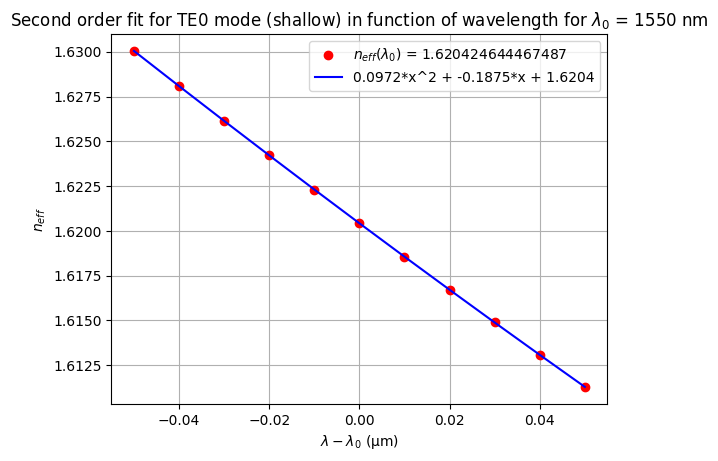

In [57]:
# Ajuste a segundo orden 
lambda_0_latex = r'\lambda_0'
neff_latex = r'n_{eff}'
plt.plot(wavelength,res_neff_shallow[:,0].real,'ro',label=f'${neff_latex}$(${lambda_0_latex}$) = {res_neff_shallow[5,0].real}')

p_TE = np.polyfit(wavelength,res_neff_shallow[:,0].real,2)
plt.plot(wavelength,np.polyval(p_TE, wavelength),color='blue',label=f'{round(p_TE[0], 4)}*x^2 + {round(p_TE[1], 4)}*x + {round(p_TE[2], 4)}')
lambda_0_latex = r'\lambda_0'
plt.title(f"Second order fit for TE0 mode (shallow) in function of wavelength for ${lambda_0_latex}$ = 1550 nm")
latex = r'\lambda-\lambda_0'
plt.xlabel(f'${latex}$ (μm)')
neff_latex = r'n_{eff}'
plt.ylabel(f'${neff_latex}$')
plt.grid()
plt.legend()
plt.show()

In [67]:
print(res_neff_shallow[5,0].real)
print(p_TE)
ng_TE0 = p_TE[2]-p_TE[1]*lambda_0*nm
D = -2*lambda_0*nm*p_TE[0]/(3*10**14) #La velocidad en micras por segundo!
print(f"neff_TE0_shallow = {p_TE[2]}")
print(f"ng_TE0_shallow= {ng_TE0}")
print(f"D_TE0_shallow = {D}")

1.620424644467487
[ 0.0971754  -0.18751823  1.62042465]
neff_TE0_shallow = 1.6204246472537591
ng_TE0_shallow= 1.911077898070884
D_TE0_shallow = -1.0041458132773847e-15


In [ ]:
ng_TE0 = p_TE[2] - p_TE[1] * lambda_0 * nm
D = -2 * lambda_0 * nm * p_TE[0] / (3 * 10**14)
D_m = D*1e12
# Display results in LaTeX format
display(Math(rf'n_{{\mathrm{{eff,TE0}}}} = {p_TE[2]:.6f}'))

display(Math(rf'n_{{g,\mathrm{{TE0}}}} = {ng_TE0:.6f}\;\frac{{1}}{{ m}}'))

display(Math(rf'D_{{\mathrm{{TE0}}}} = {D_m:.6f}\;\frac{{s}}{{m^2}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

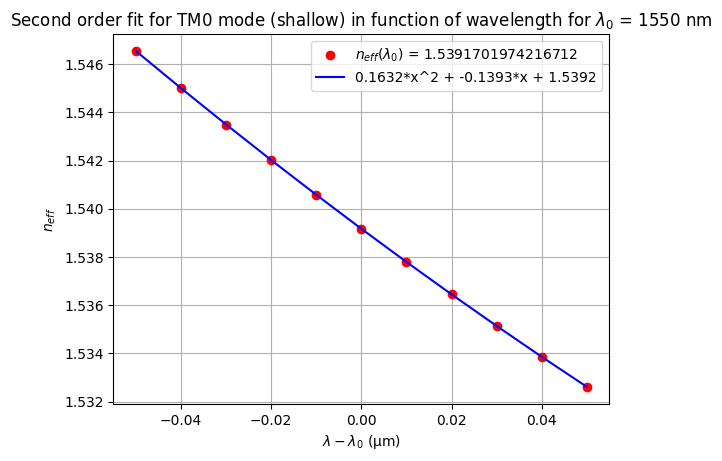

In [61]:
# Ajuste a segundo orden 
lambda_0_latex = r'\lambda_0'
neff_latex = r'n_{eff}'
plt.plot(wavelength,res_neff_shallow[:,1].real,'ro',label=f'${neff_latex}$(${lambda_0_latex}$) = {res_neff_shallow[5,1].real}')

p_TM = np.polyfit(wavelength,res_neff_shallow[:,1].real,2)
plt.plot(wavelength,np.polyval(p_TM, wavelength),color='blue',label=f'{round(p_TM[0], 4)}*x^2 + {round(p_TM[1], 4)}*x + {round(p_TM[2], 4)}')
lambda_0_latex = r'\lambda_0'
plt.title(f"Second order fit for TM0 mode (shallow) in function of wavelength for ${lambda_0_latex}$ = 1550 nm")
latex = r'\lambda-\lambda_0'
plt.xlabel(f'${latex}$ (μm)')
neff_latex = r'n_{eff}'
plt.ylabel(f'${neff_latex}$')
plt.grid()
plt.legend()
plt.show()

In [70]:
print(res_neff_shallow[5,1].real)
print(p_TM)
ng_TM0 = p_TM[2]-p_TM[1]*lambda_0*nm
D = -2*lambda_0*nm*p_TM[0]/(3*10**14) #La velocidad en micras por segundo!
print(f"neff_TM0_shallow = {p_TM[2]}")
print(f"ng_TM0_shallow= {ng_TM0}")
print(f"D_TM0_shallow = {D} unidades")

1.5391701974216712
[ 0.16319377 -0.13934873  1.53917048]
neff_TM0_shallow = 1.5391704810377564
ng_TM0_shallow= 1.75516101830703
D_TM0_shallow = -1.6863355896214938e-15 unidades


In [71]:
ng_TM0 = p_TM[2] - p_TM[1] * lambda_0 * nm
D = -2 * lambda_0 * nm * p_TM[0] / (3 * 10**14)
D_m = D*1e12
# Display results in LaTeX format
display(Math(rf'n_{{\mathrm{{eff,TM0}}}} = {p_TM[2]:.6f}'))

display(Math(rf'n_{{g,\mathrm{{TM0}}}} = {ng_TM0:.6f}\;\frac{{1}}{{\mu m}}'))

display(Math(rf'D_{{\mathrm{{TM0}}}} = {D_m:.6f}\;\frac{{s}}{{m^2}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

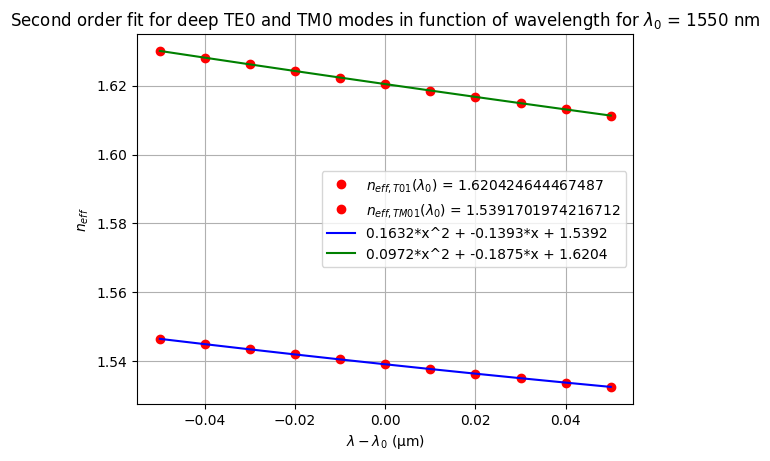

In [65]:
#Combine plot

# Ajuste a segundo orden 
lambda_0_latex = r'\lambda_0'
neff_latex_T01 = r'n_{eff,T01}'
neff_latex_TM01 = r'n_{eff,TM01}'
plt.plot(wavelength,res_neff_shallow[:,0].real,'ro',label=f'${neff_latex_T01}$(${lambda_0_latex}$) = {res_neff_shallow[5,0].real}')
plt.plot(wavelength,res_neff_shallow[:,1].real,'ro',label=f'${neff_latex_TM01}$(${lambda_0_latex}$) = {res_neff_shallow[5,1].real}')

p_TM = np.polyfit(wavelength,res_neff_shallow[:,1].real,2)
plt.plot(wavelength,np.polyval(p_TM, wavelength),color='blue',label=f'{round(p_TM[0], 4)}*x^2 + {round(p_TM[1], 4)}*x + {round(p_TM[2], 4)}')
p_TE = np.polyfit(wavelength,res_neff_shallow[:,0].real,2)
plt.plot(wavelength,np.polyval(p_TE, wavelength),color='green',label=f'{round(p_TE[0], 4)}*x^2 + {round(p_TE[1], 4)}*x + {round(p_TE[2], 4)}')

lambda_0_latex = r'\lambda_0'
plt.title(f"Second order fit for deep TE0 and TM0 modes in function of wavelength for ${lambda_0_latex}$ = 1550 nm")
latex = r'\lambda-\lambda_0'
plt.xlabel(f'${latex}$ (μm)')
neff_latex = r'n_{eff}'
plt.ylabel(f'${neff_latex}$')
plt.grid()
plt.legend()
plt.show()

## LO.4. Bend waveguide radius vs. loss – deep

The bend loss has three primary contributions:

1. Mode-mismatch loss
2. Radiation loss
3. Propagation loss

2026-11-06 09:53:02.719 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_31677371a9508407.npz.


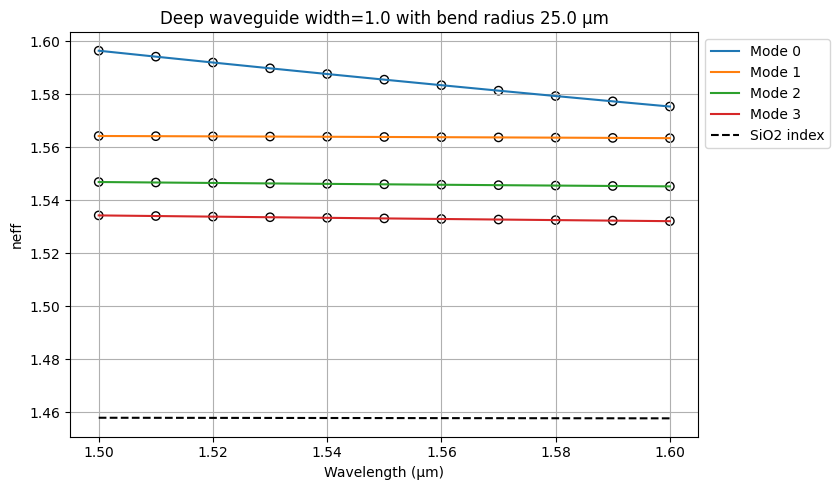

In [32]:
wavelength = np.linspace(1500, 1600,11) * nm
bend_wave = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=1,
    slab_thickness=0.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.4,
    grid_resolution=20, 
    bend_radius=25, # Bend radius
)
res_neff_bend = bend_wave.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te_bend = bend_wave.fraction_te # Wavelength-dependent vector
res_tm_bend =bend_wave.fraction_tm # Wavelength-dependent vector

plt.figure(figsize=(10, 5))
for k in range(res_neff_bend.shape[1]):
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength, res_neff_bend[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, res_neff_bend[:,k].real,label=f'Mode {k}')
plt.title(f"Deep waveguide width={bend_wave.core_width} with bend radius {bend_wave.bend_radius} μm")
plt.xlabel("Wavelength (μm)")
plt.ylabel("neff")
plt.grid()
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

A bend makes that some modes that wouldnt be excited in a atraight guide are excited in the bend one!!

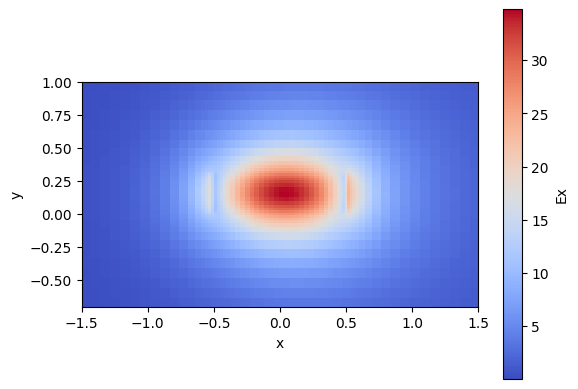

In [33]:
bend_wave.plot_field(field_name="Ex", 
                     mode_index=0, # Field to be plotted
                     value='abs', # Real - abs - imag
                     cmap='coolwarm',
                     xlim=(-1.5, 1.5), # Set the x and y limits
                     ylim=(-0.7, 1)) 

In [34]:
res_te_bend

array([0.99269679, 0.99939088, 0.99998964, 0.0012036 ])

In [8]:
res_tm_bend

array([7.30321268e-03, 6.09124562e-04, 1.03588353e-05, 9.98796397e-01])

The TM01 mode is the forth one in the list obtained!

### Mode-mismatch loss

Bend waveguide mode differs slightly from the straight waveguide mode, wich yield into mode-convertion losses. We can calculate this factor with as the overlap of the latter two modes. 

This is already implemented on GDSfactory library: 

How I compute the overlap between different modes? Because I want the TM. One option is to the overlap method. I have defined the bend radius, let's do the straight one

In [ ]:
straight_1550= gt.modes.Waveguide(
    wavelength=1550*nm,
    core_width=1,
    slab_thickness=0.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.4,
    grid_resolution=20, 
    #bend_radius=25, # Bend radius
)

straight_1550.fraction_te

2026-11-05 19:28:54.321 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_7e587402a4486fdc.npz.


array([0.99274932, 0.01076241, 0.91240641, 0.11001466])

Look! Bend radius changes the polarization! Let's consider TM01 the second mode, however, as we saw, this will change with radius

In [36]:
bend_1550= gt.modes.Waveguide(
    wavelength=1550*nm,
    core_width=1,
    slab_thickness=0.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.4,
    grid_resolution=20, 
    bend_radius=25, # Bend radius
)

In [58]:
%%capture
# Note, this code do not use cache
# Also be careful with the wavelenght with you define the waveguide, if it's a array, this method will take some time to run, because it will calculate the modes for each wavelength.
radii = np.arange(25, 150, 6) 

mismatch = gt.modes.sweep_bend_mismatch(bend_1550,
                                        radii)

In [59]:
mismatch.shape

(21, 4)

Text(0, 0.5, 'Mismatch (dB)')

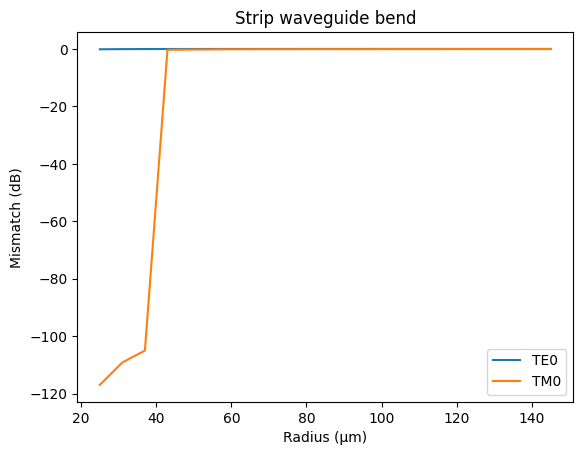

In [60]:
plt.plot(radii, 10 * np.log10(mismatch[:,0]),label='TE0')
plt.plot(radii, 10 * np.log10(mismatch[:,1]),label='TM0')
plt.legend()
plt.title("Strip waveguide bend")
plt.xlabel("Radius (μm)")
plt.ylabel("Mismatch (dB)")

Wow, for TM mode for less than 50 microsn of radi we have a disaster! To a better analysys of the result i will ommit for TM radius smaller than 50 microns

Text(0, 0.5, 'Mismatch (dB)')

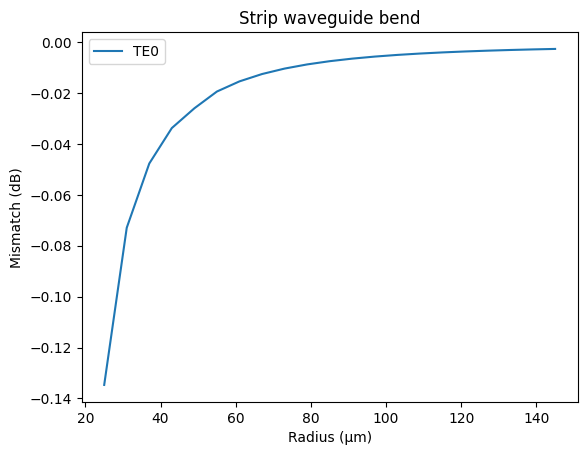

In [61]:
plt.plot(radii, 10 * np.log10(mismatch[:,0]),label='TE0')
#plt.plot(radii, 10 * np.log10(mismatch[:,1]),label='TM0')
plt.legend()
plt.title("Strip waveguide bend")
plt.xlabel("Radius (μm)")
plt.ylabel("Mismatch (dB)")

For 25 microns for TE0 we have a 0.14 db for bend, if we do a spiral, after a lot of bends I will be without light!

### Propagation loss

Consider the equivalent linear length of the quarter-circle bend. Light will attenuate following a trend quantified with the experimentally measured parameter $$\alpha [\mathrm{dB}/\mathrm{cm}]$$. It depends on the fabrication process mainly. We will add this loss (in dBs) to the mode-mismatch loss to calculate the total loss per bend. 

*We are not considering the radiation losses, mainly because is not easy to implement a quick simulation for this parameter. Under certain conditions, the main loss sources are the ones considered in this example


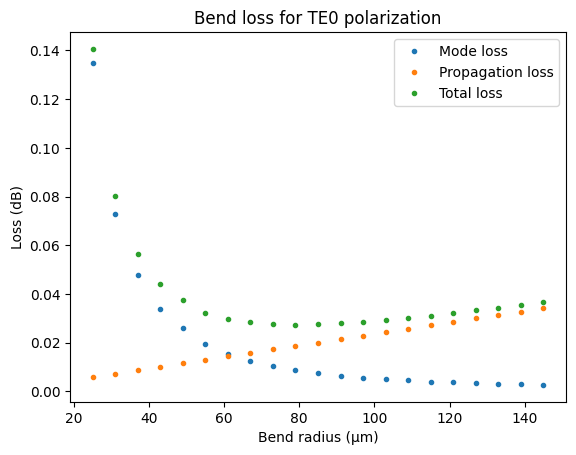

In [62]:
dB_cm = 1.5  # dB/cm Technology loss - 
length = 0.5 * np.pi * radii * 1e-6 #quarter circle perimeter in fucntion radius
propagation_loss = dB_cm * length * 1e2 #Microns to centimeters
propagation_loss

plt.title("Bend loss for TE0 polarization")
plt.plot(radii, -10 * np.log10(mismatch[:,0]), ".", label="Mode loss")
plt.plot(radii, propagation_loss, ".", label="Propagation loss")
plt.plot(radii, propagation_loss-10 * np.log10(mismatch[:,0]), ".", label="Total loss")
plt.xlabel("Bend radius (μm)")
plt.ylabel("Loss (dB)")
plt.legend()

In [66]:
mismatch[:,1][3:]

array([0.93044387, 0.94851653, 0.95981891, 0.96724328, 0.97237568,
       0.97606981, 0.97881822, 0.98091957, 0.98256308, 0.98387329,
       0.98493491, 0.98580723, 0.98653279, 0.98714276, 0.98766039,
       0.9881034 , 0.98848541, 0.98881705])

In [67]:
radii[3:]

array([ 43,  49,  55,  61,  67,  73,  79,  85,  91,  97, 103, 109, 115,
       121, 127, 133, 139, 145])

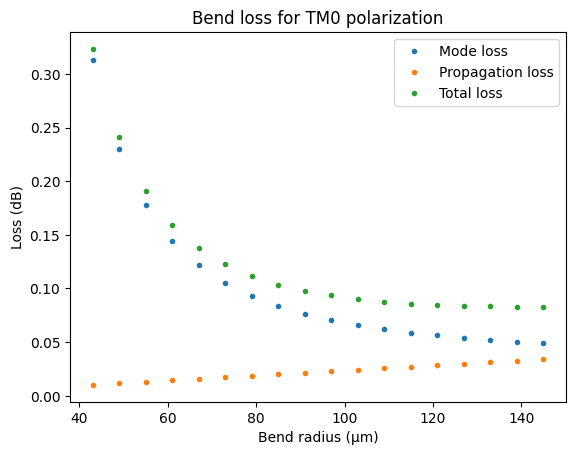

In [68]:
dB_cm = 1.5  # dB/cm Technology loss - 
length = 0.5 * np.pi * radii[3:] * 1e-6 #quarter circle perimeter in fucntion radius
propagation_loss = dB_cm * length * 1e2 #Microns to centimeters
propagation_loss

plt.title("Bend loss for TM0 polarization")
plt.plot(radii[3:], -10 * np.log10(mismatch[:,1][3:]), ".", label="Mode loss")
plt.plot(radii[3:], propagation_loss, ".", label="Propagation loss")
plt.plot(radii[3:], propagation_loss-10 * np.log10(mismatch[:,1][3:]), ".", label="Total loss")
plt.xlabel("Bend radius (μm)")
plt.ylabel("Loss (dB)")
plt.legend()

- Use the code provided in this section to calculate the safe radius for 1.2 um width deep waveguides at 1.5 um -> This was just to run the code already made. In the NoteBook PowerPoint ask us the safe radius fro width 1 micron an 25-150 microns of radius that it's the plot above. Let's see the TM polarization

## EXTRA

All the past simulations were done considering as core material de Silicon Nitride (SiNx) and Silicon Dioxide (SiO2) as cladding material. Now, **simulate the Silicon-On-Insulator technology changing the core material to Silicon (Si)**. In this case, the dimensions will be 220 nm heigth and 500 nm width. 
1. Repeat the LO.1. wavelength behavior simulations, considering the updated materials and dimensions. 
2. Repeat the LO.3. width dependence analysis, now sweeping in a 300nm - 1um range. 
3. Find the safe radius for this technology. Consider sweeping the radius in a 5um to 30um range. 
4. **Compare the SiNx and SOI technologies** 

In [153]:
si_complex = td.material_library["cSi"]["Li1993_293K"].eps_model(f)
## Check the Tidy3D Docs for more information on the "Variant"

## Index at a particular wavelength
si_index , si_k = td.Medium.eps_complex_to_nk(si_complex)

### L0.1 Effective index of a waveguide

In [161]:
grid_resolution = np.linspace(10,100,10)
max_grid_scaling = np.linspace(1.2,1.6,5)

n_eff = []
fraction_te = []

In [162]:
for grid_res in grid_resolution:
    deep_waveguide = gt.modes.Waveguide(
        # Geometrical Parameters
        core_width=500*nm, # Waveguide width
        core_thickness=220 * nm, # Waveguide height 
        slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
        # Materials
        core_material='si', #  Material of the waveguide-> We put silicon
        clad_material='sio2', # Surrounding material
        # Modesolver Parameters
        wavelength=1550 * nm, # Wavelength to simulate
        num_modes=4, # Targeted number of modes to find 
        max_grid_scaling=1.5, # Parameters of the grid 
        grid_resolution=grid_res, # Parameters of the grid
        cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
        precision='double',
    )

    #deep_waveguide.plot_index()
    n_eff.append(deep_waveguide.n_eff)
    fraction_te.append(deep_waveguide.fraction_te)

2026-11-05 20:50:03.580 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_555496046cbcf8ad.npz.
2026-11-05 20:50:03.581 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_9b607c2ee0ef414d.npz.
2026-11-05 20:50:03.583 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_0866d3aa55a99d6e.npz.
2026-11-05 20:50:03.585 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_b6d52bd5523d441b.npz.
2026-11-05 20:50:03.586 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_2e7d1521ebf07a15.npz.
2026-11-05 20:50:03.587 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_ba0e1285093a72b6.npz.
2026-11-05 20:50:03.588 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_3700896b1b09c109.npz.
2026-11-05 20:50:03.589 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_85555abca54fa391.npz.


In [163]:
fraction_te

[array([0.98003   , 0.05790162, 0.71450974, 0.99086227]),
 array([0.97579525, 0.06630413, 0.71276936, 0.99259802]),
 array([0.97946251, 0.06391456, 0.72218522, 0.99255343]),
 array([0.97706623, 0.06787034, 0.70302788, 0.99419284]),
 array([0.97737196, 0.06806412, 0.69752411, 0.99492429]),
 array([0.98014787, 0.06236716, 0.7045566 , 0.99472012]),
 array([0.98107114, 0.06273807, 0.70077361, 0.99541688]),
 array([0.98001812, 0.06358437, 0.69428619, 0.99587121]),
 array([0.98284143, 0.05919911, 0.70437765, 0.99565301]),
 array([0.98377773, 0.05877176, 0.70235316, 0.996106  ])]

In [164]:
n_eff 

[array([2.45507396+5.08218044e-05j, 1.78953512+2.34707155e-04j,
        1.50802141+1.98807569e-04j, 1.43542107+2.17529141e-04j]),
 array([2.44861457+5.18814919e-05j, 1.79072971+2.33412154e-04j,
        1.50655788+1.98972485e-04j, 1.43326339+2.17759708e-04j]),
 array([2.48886076+4.69840570e-05j, 1.83779056+2.18419086e-04j,
        1.51953109+1.96775565e-04j, 1.43278243+2.17744292e-04j]),
 array([2.44662796+5.22359357e-05j, 1.78697941+2.34269589e-04j,
        1.50562105+1.99180833e-04j, 1.43209178+2.17866126e-04j]),
 array([2.42711425+5.41574456e-05j, 1.76141717+2.41925548e-04j,
        1.5003524 +1.99555722e-04j, 1.43171828+2.17923866e-04j]),
 array([2.46278957+5.06590203e-05j, 1.80745072+2.27447636e-04j,
        1.50990725+1.98911236e-04j, 1.43180352+2.17867580e-04j]),
 array([2.44696672+5.21905629e-05j, 1.7855374 +2.34498577e-04j,
        1.50544063+1.99226884e-04j, 1.43157848+2.17909917e-04j]),
 array([2.43067627+5.42804099e-05j, 1.76788686+2.39529400e-04j,
        1.5007851 +1.99925

In [165]:
n_eff_TE0 = []
for i in range(len(n_eff)):
    n_eff_TE0.append(n_eff[i][0].real)

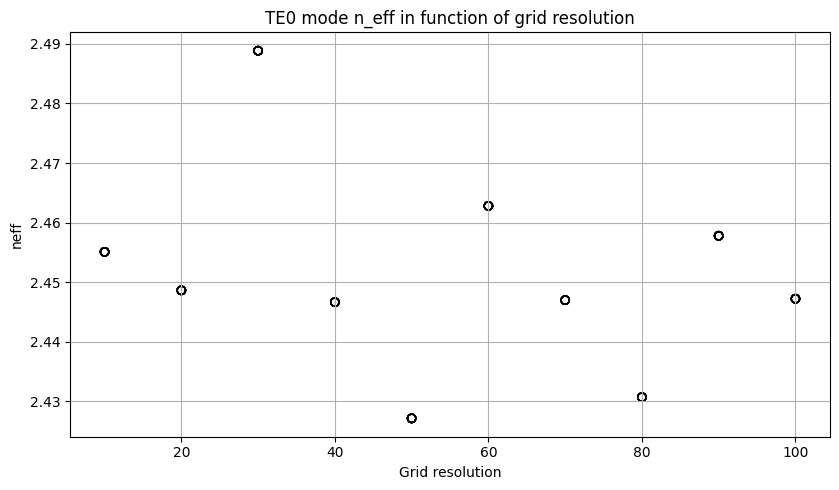

In [166]:
plt.figure(figsize=(10, 5))
for k in range(len(grid_resolution)):
    # It's necessary to 'access' each element on the array
    plt.scatter(grid_resolution, n_eff_TE0,edgecolors='k',facecolors='none',label = '__nolegend__')
    #plt.plot(grid_resolution, n_eff_TE0,label=f'Mode {k}')
plt.title(f"TE0 mode n_eff in function of grid resolution")
plt.xlabel("Grid resolution")
plt.ylabel("neff")
plt.grid()
#plt.plot(grid_resolution, box_index,'k--', label='SiO2 index')
#plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

Wow, we see apretty random convergence, let's choose 20 because it seems to be in the imaginary mean of this variations and for analogy of the SiN case

In [169]:
n_eff = []
fraction_te = []
for max_grid in max_grid_scaling:
    deep_waveguide = gt.modes.Waveguide(
        # Geometrical Parameters
        core_width=500*nm, # Waveguide width
        core_thickness=220 * nm, # Waveguide height 
        slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
        # Materials
        core_material='si', #  Material of the waveguide
        clad_material='sio2', # Surrounding material
        # Modesolver Parameters
        wavelength=1550 * nm, # Wavelength to simulate
        num_modes=4, # Targeted number of modes to find 
        max_grid_scaling=max_grid, # Parameters of the grid 
        grid_resolution=20, # Parameters of the grid
        cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
        precision='double',
    )

    #deep_waveguide.plot_index()
    n_eff.append(deep_waveguide.n_eff)
    fraction_te.append(deep_waveguide.fraction_te)

2026-11-05 20:57:19.047 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_223d93916735b32f.npz.
2026-11-05 20:57:19.057 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_2b23fbc3e6bc4a22.npz.
2026-11-05 20:57:19.065 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d2a12d2520042e19.npz.
2026-11-05 20:57:19.072 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_9b607c2ee0ef414d.npz.
2026-11-05 20:57:19.073 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_02d6f234e1cf89a5.npz.


In [170]:
n_eff_TE0 = []
for i in range(len(n_eff)):
    n_eff_TE0.append(n_eff[i][0].real)

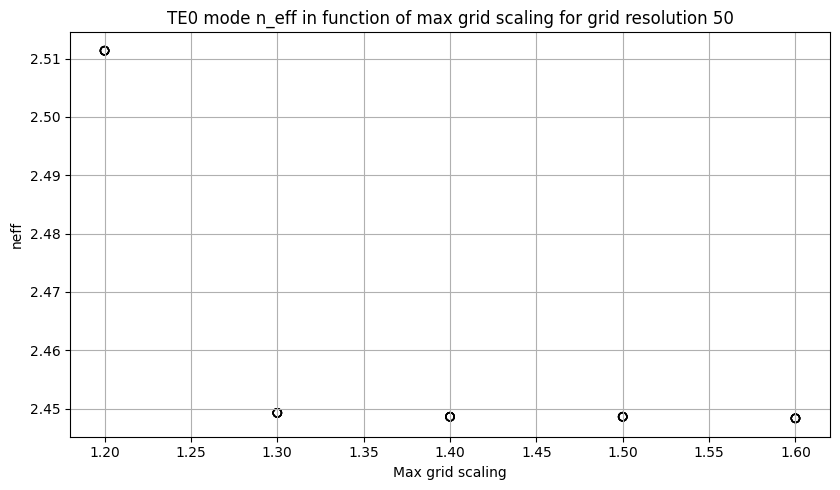

In [171]:
plt.figure(figsize=(10, 5))
for k in range(len(max_grid_scaling)):
    # It's necessary to 'access' each element on the array
    plt.scatter(max_grid_scaling, n_eff_TE0,edgecolors='k',facecolors='none',label = '__nolegend__')
    #plt.plot(max_grid_scaling, n_eff_TE0,label=f'Mode {k}')
plt.title(f"TE0 mode n_eff in function of max grid scaling for grid resolution 50")
plt.xlabel("Max grid scaling")
plt.ylabel("neff")
plt.grid()
#plt.plot(grid_resolution, box_index,'k--', label='SiO2 index')
#plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

We will choose max grid scaling 1.4 to analogy of SiN case and because it seem that converges

### L0.2 Width dependence

  0%|          | 0/8 [00:00<?, ?it/s]

2026-11-05 21:00:16.393 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_e8043bc2d10bd84d.npz.
2026-11-05 21:00:16.395 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_fa397ef17301ec27.npz.
2026-11-05 21:00:16.396 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d2a12d2520042e19.npz.
2026-11-05 21:00:16.398 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_0b5fcd1855de992f.npz.
2026-11-05 21:00:16.400 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_191f4262935b7aa5.npz.
2026-11-05 21:00:16.401 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_bfd6250c8a84f226.npz.
2026-11-05 21:00:16.402 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_646dee63e8743ae9.npz.
2026-11-05 21:00:16.404 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_f9531d79003df39f.npz.


  0%|          | 0/8 [00:00<?, ?it/s]

2026-11-05 21:00:16.408 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_e8043bc2d10bd84d.npz.
2026-11-05 21:00:16.409 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_fa397ef17301ec27.npz.
2026-11-05 21:00:16.410 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d2a12d2520042e19.npz.
2026-11-05 21:00:16.412 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_0b5fcd1855de992f.npz.
2026-11-05 21:00:16.413 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_191f4262935b7aa5.npz.
2026-11-05 21:00:16.414 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_bfd6250c8a84f226.npz.
2026-11-05 21:00:16.415 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_646dee63e8743ae9.npz.
2026-11-05 21:00:16.417 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_f9531d79003df39f.npz.


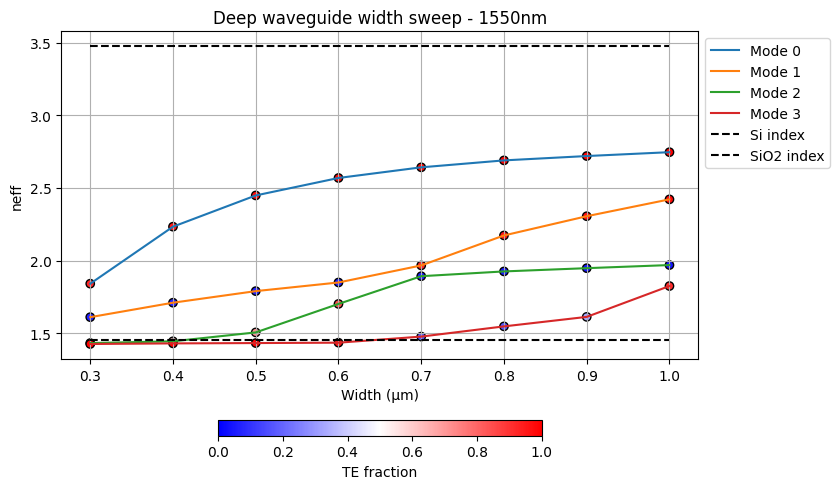

In [173]:
wavelength = 1550 * nm # Student code here

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=500*nm,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    slab_thickness=0 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.4,
    grid_resolution=20, 
)

w = np.linspace(0.3,1,8) # Student code here

sweep_neff = gt.modes.sweep_n_eff(deep_waveguide, 
                             core_width=w)

sweep_tefraction = gt.modes.sweep_fraction_te(deep_waveguide,
                                              core_width=w)

plt.figure(figsize=(10, 5))
for k in range(sweep_neff.shape[1]):
    plt.scatter(w, sweep_neff[:,k].real,edgecolors='k',c=sweep_tefraction.sel(mode_index=k),vmin=0, vmax=1,label = '__nolegend__',cmap='bwr')
    plt.plot(w, sweep_neff[:,k].real,label=f'Mode {k}')

plt.title("Deep waveguide width sweep - 1550nm")
plt.xlabel("Width (μm)")
plt.ylabel("neff")
plt.grid()
plt.hlines(np.mean(si_index), xmin=np.min(w), xmax=np.max(w), colors='k', linestyles='dashed',label='Si index')
plt.hlines(np.mean(box_index), xmin=np.min(w), xmax=np.max(w), colors='k', linestyles='dashed',label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.colorbar(orientation='horizontal',fraction=0.04).set_label("TE fraction")

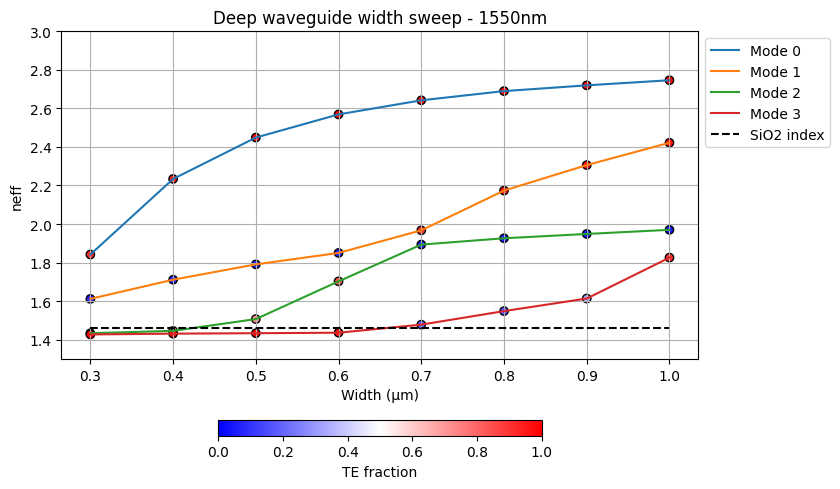

In [175]:
plt.figure(figsize=(10, 5))
for k in range(sweep_neff.shape[1]):
    plt.scatter(w, sweep_neff[:,k].real,edgecolors='k',c=sweep_tefraction.sel(mode_index=k),vmin=0, vmax=1,label = '__nolegend__',cmap='bwr')
    plt.plot(w, sweep_neff[:,k].real,label=f'Mode {k}')

plt.title("Deep waveguide width sweep - 1550nm")
plt.xlabel("Width (μm)")
plt.ylabel("neff")
plt.grid()
#plt.hlines(np.mean(si_index), xmin=np.min(w), xmax=np.max(w), colors='k', linestyles='dashed',label='Si index')
plt.hlines(np.mean(box_index), xmin=np.min(w), xmax=np.max(w), colors='k', linestyles='dashed',label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.ylim(1.3,3)
plt.colorbar(orientation='horizontal',fraction=0.04).set_label("TE fraction")

In [178]:
sweep_tefraction

<xarray.DataArray 'fraction_te' (core_width: 8, mode_index: 4)> Size: 256B
array([[0.92071636, 0.07275571, 0.5222007 , 0.99476638],
       [0.95333419, 0.07265972, 0.59810199, 0.99937219],
       [0.9757289 , 0.06650902, 0.71269539, 0.99262251],
       [0.98627882, 0.06139698, 0.84396681, 0.96073136],
       [0.99168279, 0.9200727 , 0.05508203, 0.17058747],
       [0.99455751, 0.95798204, 0.04739353, 0.16525368],
       [0.99564113, 0.97065295, 0.0427285 , 0.3258448 ],
       [0.99731748, 0.98344295, 0.03792448, 0.91173387]])
Coordinates:
  * core_width  (core_width) float64 64B 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.0
  * mode_index  (mode_index) int64 32B 0 1 2 3

What, we found that the same mode depending the width changes polarization? How can be this. MAybe a error selecting the grid parameters and I am not in a convergent solution?

### L0.3. Waveguide compact mode

#### Deep waveguide


2026-11-05 21:22:29.062 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_e24dc57b500a9e38.npz.


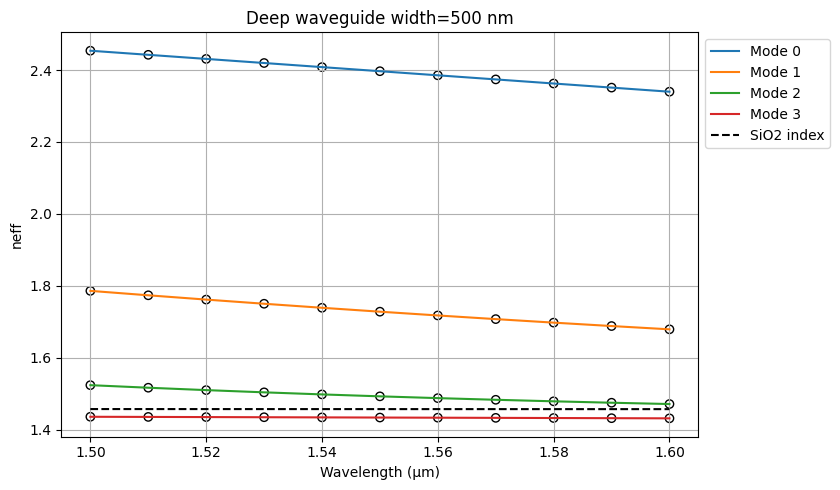

In [181]:
# The wavelength could be a vector also
wavelength = np.linspace(1500, 1600,11) * nm

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength, 
    core_width=500*nm, 
    slab_thickness=0.0,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.4,
    grid_resolution=20, 
)

res_neff = deep_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te = deep_waveguide.fraction_te # Wavelength-dependent vector
res_tm =deep_waveguide.fraction_tm # Wavelength-dependent vector

plt.figure(figsize=(10, 5))
for k in range(res_neff.shape[1]):
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength, res_neff[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, res_neff[:,k].real,label=f'Mode {k}')
plt.title(f"Deep waveguide width={500} nm")
plt.xlabel("Wavelength (μm)")
plt.ylabel("neff")
plt.grid()
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

In [184]:
res_te

array([0.97490295, 0.06603169, 0.70543521, 0.99456164])

In [183]:
lambda_0 = 1550
wavelength = wavelength = np.linspace(1500, 1600,11) 
wavelength = wavelength -1550
wavelength = wavelength * nm
print(wavelength)

[-0.05 -0.04 -0.03 -0.02 -0.01  0.    0.01  0.02  0.03  0.04  0.05]


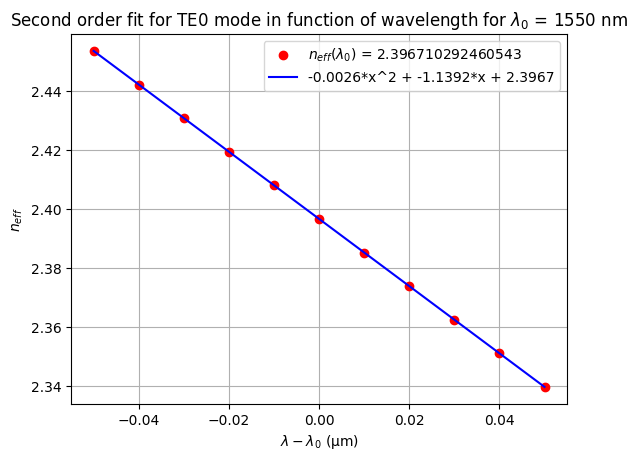

In [185]:
# Ajuste a segundo orden 
lambda_0_latex = r'\lambda_0'
neff_latex = r'n_{eff}'
plt.plot(wavelength,res_neff[:,0].real,'ro',label=f'${neff_latex}$(${lambda_0_latex}$) = {res_neff[5,0].real}')

p = np.polyfit(wavelength,res_neff[:,0].real,2)
plt.plot(wavelength,np.polyval(p, wavelength),color='blue',label=f'{round(p[0], 4)}*x^2 + {round(p[1], 4)}*x + {round(p[2], 4)}')
lambda_0_latex = r'\lambda_0'
plt.title(f"Second order fit for TE0 mode in function of wavelength for ${lambda_0_latex}$ = 1550 nm")
latex = r'\lambda-\lambda_0'
plt.xlabel(f'${latex}$ (μm)')
neff_latex = r'n_{eff}'
plt.ylabel(f'${neff_latex}$')
plt.grid()
plt.legend()
plt.show()

In [186]:
print(res_neff[5,0].real)
print(p)
ng_TE0 = p[2]-p[1]*lambda_0*nm
D = -2*lambda_0*nm*p[0]/(3*10**14) #La velocidad en micras por segundo!
print(f"neff_TE0_deep = {p[2]}")
print(f"ng_TE0_deep= {ng_TE0}")
print(f"D_TE0_deep = {D}")

2.396710292460543
[-0.00256921 -1.13915314  2.39671012]
neff_TE0_deep = 2.3967101216509596
ng_TE0_deep= 4.162397488730159
D_TE0_deep = 2.6548537084713676e-17


In [189]:
ng_TE0 = p[2] - p[1] * lambda_0 * nm
D = -2 * lambda_0 * nm * p[0] / (3 * 10**14)
D_m = D*1e12
# Display results in LaTeX format
display(Math(rf'n_{{\mathrm{{eff,TE0}}}} = {p[2]:.6f}'))

display(Math(rf'n_{{g,\mathrm{{TE0}}}} = {ng_TE0:.6f}\;\frac{{1}}{{\mu m}}'))

display(Math(rf'D_{{\mathrm{{TE0}}}} = {D_m:.6f}\;\frac{{s}}{{m^2}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

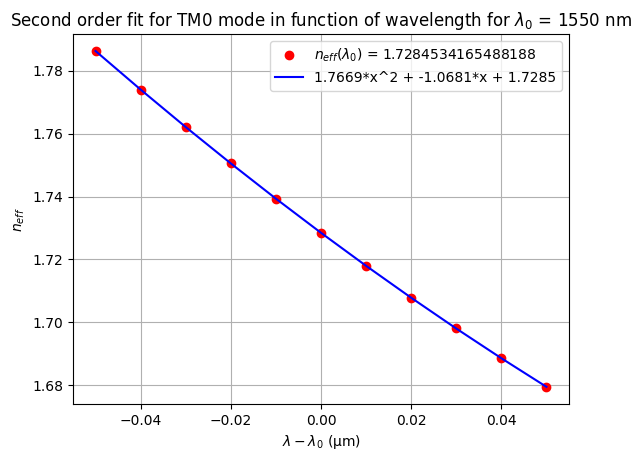

In [190]:
# Ajuste a segundo orden 
lambda_0_latex = r'\lambda_0'
neff_latex = r'n_{eff}'
plt.plot(wavelength,res_neff[:,1].real,'ro',label=f'${neff_latex}$(${lambda_0_latex}$) = {res_neff[5,1].real}')

p_TM = np.polyfit(wavelength,res_neff[:,1].real,2)
plt.plot(wavelength,np.polyval(p_TM, wavelength),color='blue',label=f'{round(p_TM[0], 4)}*x^2 + {round(p_TM[1], 4)}*x + {round(p_TM[2], 4)}')
lambda_0_latex = r'\lambda_0'
plt.title(f"Second order fit for TM0 mode in function of wavelength for ${lambda_0_latex}$ = 1550 nm")
plt.xlabel(f'${latex}$ (μm)')
plt.ylabel(f'${neff_latex}$')
plt.grid()
plt.legend()
plt.show()

In [191]:
print(res_neff[5,1].real)
print(p_TM)
ng_TM0 = p_TM[2]-p_TM[1]*lambda_0*nm
D = -2*lambda_0*nm*p_TM[0]/(3*10**14) #La velocidad en micras por segundo!
print(f"neff_TM0_deep = {p_TM[2]}")
print(f"ng_TM0_deep= {ng_TM0}")
print(f"D_TM0_deep = {D}")

1.7284534165488188
[ 1.76688396 -1.06806018  1.72845538]
neff_TM0_deep = 1.7284553770214481
ng_TM0_deep= 3.3839486562741055
D_TM0_deep = -1.8257800898039972e-14


In [192]:
ng_TM0 = p_TM[2] - p_TM[1] * lambda_0 * nm
D = -2 * lambda_0 * nm * p_TM[0] / (3 * 10**14)
D_m = D*1e12
# Display results in LaTeX format
display(Math(rf'n_{{\mathrm{{eff,TM0}}}} = {p_TM[2]:.6f}'))

display(Math(rf'n_{{g,\mathrm{{TM0}}}} = {ng_TM0:.6f}\;\frac{{1}}{{\mu m}}'))

display(Math(rf'D_{{\mathrm{{TM0}}}} = {D_m:.6f}\;\frac{{s}}{{m^2}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### Shallow waveguide


As we mentioned in the previous section, we will work with the same grid parameters as the deep guide.

c:\Users\cfp\Desktop\David\Diseño\LAB\Sesion4\pic-upv-lab1\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\cfp\Desktop\David\Diseño\LAB\Sesion4\pic-upv-lab1\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\Users\cfp\Desktop\David\Diseño\LAB\Sesion4\p

10:30:17 Hora estándar romance WARNING: Mode '19' appears to undergo a          
                               discontinuous change between frequencies         
                               '194670427272727.28' and '193414489032258.06'    
                               (overlap: '0.01').                               

                               WARNING: Mode '19' appears to undergo a          
                               discontinuous change between frequencies         
                               '195942783006535.94' and '194670427272727.28'    
                               (overlap: '0.87').                               

10:30:19 Hora estándar romance WARNING: Mode '11' appears to undergo a          
                               discontinuous change between frequencies         
                               '189742062025316.44' and '190950610191082.78'    
                               (overlap: '0.87').                               

                               WARNING: Mode '12' appears to undergo a          
                               discontinuous change between frequencies         
                               '189742062025316.44' and '190950610191082.78'    
                               (overlap: '0.88').                               

10:30:20 Hora estándar romance WARNING: Mode field at frequency index 0, mode   
                               index 1 does not decay at the plane boundaries.  

... (155 outputs left out)

                               WARNING: Mode field at frequency index 10, mode  
                               index 17 does not decay at the plane boundaries. 

                               WARNING: Mode field at frequency index 10, mode  
                               index 18 does not decay at the plane boundaries. 

                               WARNING: Mode field at frequency index 10, mode  
                               index 19 does not decay at the plane boundaries. 

2026-11-06 10:30:31.026 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\Waveguide_8e420df3bd60006e.npz.


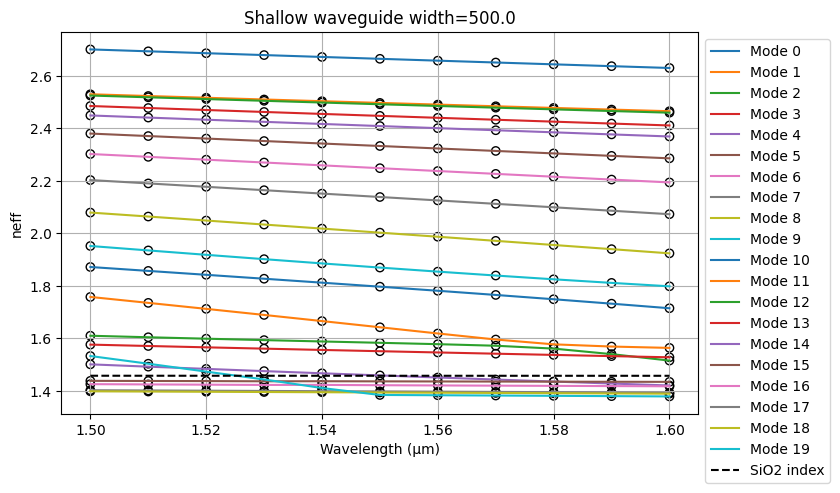

In [69]:
# The wavelength could be a vector also
wavelength = np.linspace(1500, 1600,11) * nm

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength, 
    core_width=500*nm, 
    slab_thickness=150*nm,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    num_modes=20,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.4,
    grid_resolution=20, 
)

res_neff = deep_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te = deep_waveguide.fraction_te # Wavelength-dependent vector
res_tm =deep_waveguide.fraction_tm # Wavelength-dependent vector

plt.figure(figsize=(10, 5))
for k in range(res_neff.shape[1]):
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength, res_neff[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, res_neff[:,k].real,label=f'Mode {k}')
plt.title(f"Shallow waveguide width={deep_waveguide.core_width/nm}")
plt.xlabel("Wavelength (μm)")
plt.ylabel("neff")
plt.grid()
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

In [70]:
res_te

array([0.98561089, 0.99559388, 0.99986132, 0.98297141, 0.99979517,
       0.97285167, 0.99971799, 0.94147236, 0.99490609, 0.22381581,
       0.25893511, 0.64857616, 0.21153142, 0.04742389, 0.12090798,
       0.00920274, 0.01296871, 0.97358559, 0.00374438, 0.9334288 ])

The TM mode is the 13 one! Before that we have some TE and Hybrid modes. Let's analyze that. So we can say that is easier to do a TM monomode fiber for Si than TE, because for this geometries we will always have various TE modes

In [196]:
lambda_0 = 1550
wavelength = wavelength = np.linspace(1500, 1600,11) 
wavelength = wavelength -1550
wavelength = wavelength * nm
print(wavelength)

[-0.05 -0.04 -0.03 -0.02 -0.01  0.    0.01  0.02  0.03  0.04  0.05]


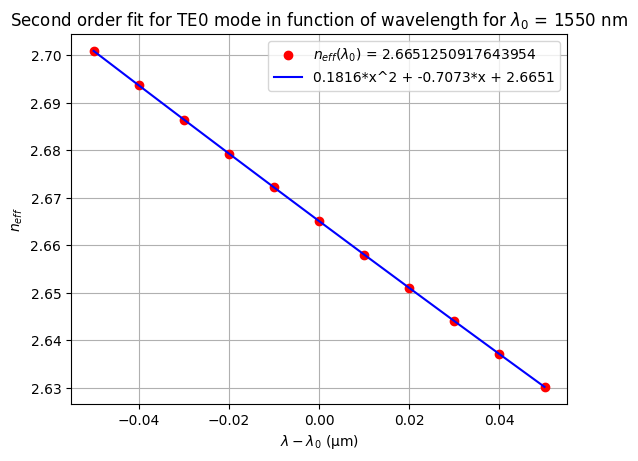

In [197]:
# Ajuste a segundo orden 
lambda_0_latex = r'\lambda_0'
neff_latex = r'n_{eff}'
plt.plot(wavelength,res_neff[:,0].real,'ro',label=f'${neff_latex}$(${lambda_0_latex}$) = {res_neff[5,0].real}')

p = np.polyfit(wavelength,res_neff[:,0].real,2)
plt.plot(wavelength,np.polyval(p, wavelength),color='blue',label=f'{round(p[0], 4)}*x^2 + {round(p[1], 4)}*x + {round(p[2], 4)}')
lambda_0_latex = r'\lambda_0'
plt.title(f"Second order fit for TE0 mode in function of wavelength for ${lambda_0_latex}$ = 1550 nm")
latex = r'\lambda-\lambda_0'
plt.xlabel(f'${latex}$ (μm)')
neff_latex = r'n_{eff}'
plt.ylabel(f'${neff_latex}$')
plt.grid()
plt.legend()
plt.show()

In [198]:
print(res_neff[5,0].real)
print(p)
ng_TE0 = p[2]-p[1]*lambda_0*nm
D = -2*lambda_0*nm*p[0]/(3*10**14) #La velocidad en micras por segundo!
print(f"neff_TE0_deep = {p[2]}")
print(f"ng_TE0_deep= {ng_TE0}")
print(f"D_TE0_deep = {D}")

2.6651250917643954
[ 0.18161244 -0.70729796  2.66512506]
neff_TE0_deep = 2.6651250639704425
ng_TE0_deep= 3.761436906486379
D_TE0_deep = -1.8766619313604558e-15


In [199]:
ng_TE0 = p[2] - p[1] * lambda_0 * nm
D = -2 * lambda_0 * nm * p[0] / (3 * 10**14)
D_m = D*1e12
# Display results in LaTeX format
display(Math(rf'n_{{\mathrm{{eff,TE0}}}} = {p[2]:.6f}'))

display(Math(rf'n_{{g,\mathrm{{TE0}}}} = {ng_TE0:.6f}\;\frac{{1}}{{\mu m}}'))

display(Math(rf'D_{{\mathrm{{TE0}}}} = {D_m:.6f}\;\frac{{s}}{{m^2}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### L0.4 Bend waveguide radius vs losses

## Grading

LO.1. 2 Point <br> 
LO.2. 1 Points <br> 
LO.3. 3 Point <br> 
LO.4. 1 Points <br> 
**Total 7 Points** <br>
Extra (Up to) 3 Points
